# 02 Split and preprocessing

Functions: `src/piece_of_crop/data.py`.

**Purpose.** Split the 27,000 patches into training, validation and test sets without leakage, and compute the normalisation statistics from the training set only.

**Reads.** The raw GeoTIFFs and `results/file_summary.csv` from notebook 01.
**Saves.** The split file (file, class, split) and the per-band statistics in `results/`. Every later notebook uses these two files, so they are created once here and not changed afterwards. When they already exist, this notebook loads and checks them instead of making new ones.

**Why.** Notebook 01 showed that patches come in tight geographic clusters, so a random split would put neighbours in both training and test data. The course separates the data into training, validation and test sets, where the test set is like "new" data never used during training (lecture_2_introduction_to_ML.pdf, slide 24). Rubric criterion 5 grades a "correct train / validation / test split (no data leakage)" (Group_Project_Guidelines_and_Rubric.pdf, marking scheme). Notebook 01 also found rare extreme values in every band, and the course asks us to "explain your normalization choice" (CNN_Class_Competition_2_Food_Classification_Explained.pdf, assignment requirements, step 5).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split

from piece_of_crop import (
    BAND_NAMES,
    CLASS_NAMES,
    apply_buffer,
    assign_blocks,
    compute_band_stats,
    list_files,
    nearest_distance_km,
    normalise,
    read_bands,
    spatial_split,
)

SEED = 0
project_root = Path.cwd().parents[0]
data_dir = project_root / "data" / "EuroSAT_MS"
results_dir = project_root / "results"
figures_dir = results_dir / "figures"

# Locations come from notebook 01. Paths are rebuilt here, so the saved files hold no personal paths.
summary = pd.read_csv(results_dir / "file_summary.csv", usecols=["file", "class_name", "label", "lon", "lat"])
patches = summary.merge(list_files(data_dir)[["file", "path"]], on="file")
print("Patches:", len(patches))
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Patches: 27000


## 1. Why a random split is not enough

The course splits the data into training, validation and test sets, where the test set is like "new" data that has never been used during training (lecture_2_introduction_to_ML.pdf, slide 24). Notebook 01 showed that the patches come in tight geographic clusters. We measure what that means for a random split: for each test patch, how far away is the nearest training patch? One patch is 64 x 10 m = 0.64 km wide.

In [2]:
random_train, random_test = train_test_split(patches, test_size=0.15, stratify=patches["label"], random_state=SEED)
random_distance = nearest_distance_km(random_test, random_train)

print(f"Random split: median distance test -> nearest train patch: {np.median(random_distance):.2f} km")
print(f"Random split: share of test patches with a train patch within 1 km: {(random_distance < 1).mean():.1%}")

Random split: median distance test -> nearest train patch: 0.92 km
Random split: share of test patches with a train patch within 1 km: 54.6%


**Claim.** A random split would leak: most test patches would have a near-identical neighbour in the training data.

**Reasons.** One patch is 0.64 km wide, so a training patch less than 1 km away is usually the patch right next to it, from the same scene, date and atmosphere.

**Evidence.** With a random 85/15 split, the median distance from a test patch to its nearest training patch is 0.92 km, and 54.6% of test patches have a training patch within 1 km.

**Warrant.** The test set must behave like "new" data never used in training (lecture_2_introduction_to_ML.pdf, slide 24). If half of the test patches have their neighbour in training, the test score partly measures how well the model remembers a scene, not how well it classifies a new parcel.

**Counterargument.** Neighbouring patches are not identical, and a model still has to generalise from them. We accept that the size of the inflation is unknown, but a test that an insurer can trust for new parcels has to exclude it.

## 2. Spatial split: choosing the block size

We lay a grid over the map and give every patch the id of its grid cell (its "block"). Whole blocks then go to one split, so neighbours stay together. The split uses `StratifiedGroupKFold` from scikit-learn (external, scikit-learn documentation), which keeps every group in one fold and keeps the class proportions as close as possible. We make 7 folds: fold 0 is the test set, fold 1 the validation set and folds 2 to 6 the training set (about 71/14/14).

Larger blocks keep neighbours apart better but make the class proportions harder to balance, because there are fewer and bigger groups to distribute. We compare four sizes.

In [3]:
class_share_all = patches["class_name"].value_counts(normalize=True)
rows = []
for block_size in [0.1, 0.25, 0.5, 1.0]:
    split = spatial_split(patches, block_size_deg=block_size, n_folds=7, seed=SEED)
    train = split[split["split"] == "train"]
    test = split[split["split"] == "test"]
    distance = nearest_distance_km(test, train)
    class_share_test = test["class_name"].value_counts(normalize=True)
    rows.append({
        "block size (degrees)": block_size,
        "blocks": split["block"].nunique(),
        "test patches": len(test),
        "median distance test -> train (km)": round(np.median(distance), 1),
        "test patches with a train patch within 1 km": f"{(distance < 1).mean():.1%}",
        "largest class-share difference in test (points)": round(100 * (class_share_test - class_share_all).abs().max(), 1),
    })
pd.DataFrame(rows)

,block size (degrees),blocks,test patches,median distance test -> train (km),test patches with a train patch within 1 km,largest class-share difference in test (points)
0,0.10,5724,3858,3.8,8.9%,0.0
1,0.25,2047,3858,7.5,2.3%,0.0
2,0.50,950,3854,14.5,1.0%,0.1
3,1.00,426,3816,23.2,0.5%,0.9


**Claim.** We use 0.5 degree blocks: they remove almost all close neighbours while keeping the class proportions of the test set essentially equal to those of the full data.

**Reasons.** Larger blocks push the test patches further from the training patches. They also leave fewer groups to share out, which makes balancing the classes harder and leaves fewer independent places to test on.

**Evidence.** From 0.1 to 1 degree, the share of test patches with a training patch within 1 km falls from 8.9% to 0.5%, and the median distance rises from 3.8 to 23.2 km. At 0.5 degrees, 1.0% of test patches still have a close neighbour, the median distance is 14.5 km and the largest class-share difference is 0.1 percentage points, against 0.9 at 1 degree with less than half the blocks (426 instead of 950).

**Warrant.** The aim is a test set without neighbours that still represents every class in the same proportion as the data. 0.5 degrees comes close to the neighbour-free result of 1 degree, and the 1% of edge neighbours left is removed by the buffer in section 3, so the extra distance of 1 degree is not needed.

**Counterargument.** 1 degree keeps test patches further away on average (23.2 km against 14.5 km), so it is the stricter test. We accept that more distance would be stricter. After the buffer, both sizes leave no training patch within 1 km of a test patch, and 0.5 degrees keeps more than twice as many blocks and closer class proportions.

## 3. Final split with a 1 km buffer

Blocks share edges, so a few patches on either side of an edge are still neighbours. We remove them: a training patch closer than 1 km to a validation or test patch, and a validation patch closer than 1 km to a test patch, are marked "buffer" and not used.

**The split is made once.** `StratifiedGroupKFold` can share out the blocks differently in another scikit-learn version, even with the same seed. So the split is made only when `results/split.csv` does not exist yet. Once it exists, this cell loads it, and every model, the evaluation and anyone re-running the project use exactly the same train, validation and test patches. The checks below run on the loaded split.

In [4]:
BLOCK_SIZE_DEG = 0.5
BUFFER_KM = 1.0
split_path = results_dir / "split.csv"

if split_path.exists():
    # The fixed split that every model is trained and tested on. Paths are added back from patches.
    split = pd.read_csv(split_path).merge(patches[["file", "path"]], on="file")
    assert len(split) == len(patches), "split.csv does not match the patches"
    print("Loaded the fixed split from results/split.csv")
else:
    split = spatial_split(patches, block_size_deg=BLOCK_SIZE_DEG, n_folds=7, seed=SEED)
    split = apply_buffer(split, buffer_km=BUFFER_KM)
    print("No results/split.csv yet: made a new split")

train = split[split["split"] == "train"]
val = split[split["split"] == "val"]
test = split[split["split"] == "test"]

print(split["split"].value_counts())
print("Blocks in more than one split:", int((split[split["split"] != "buffer"].groupby("block")["split"].nunique() > 1).sum()))
print(f"Closest train patch to any test patch: {nearest_distance_km(test, train).min():.2f} km")
print(f"Closest train patch to any val patch:  {nearest_distance_km(val, train).min():.2f} km")
print(f"Closest val patch to any test patch:   {nearest_distance_km(test, val).min():.2f} km")

split
train     19159
val        3870
test       3854
buffer      117
Name: count, dtype: int64
Closest train patch to any test patch: 1.04 km
Closest train patch to any val patch:  1.00 km
Closest val patch to any test patch:   1.09 km


In [5]:
class_table = pd.crosstab(split["class_name"], split["split"])[["train", "val", "test", "buffer"]]
share_table = (pd.crosstab(split["class_name"], split["split"], normalize="columns")[["train", "val", "test"]] * 100).round(1)
share_table.columns = [f"{c} (%)" for c in share_table.columns]
class_table.join(share_table)

,train,val,test,buffer,train (%),val (%),test (%)
class_name,,,,,,,
AnnualCrop,2137,424,429,10,11.2,11.0,11.1
Forest,2127,425,429,19,11.1,11.0,11.1
HerbaceousVegetation,2125,428,428,19,11.1,11.1,11.1
Highway,1783,357,358,2,9.3,9.2,9.3
Industrial,1782,357,357,4,9.3,9.2,9.3
Pasture,1426,285,286,3,7.4,7.4,7.4
PermanentCrop,1758,382,353,7,9.2,9.9,9.2
Residential,2133,428,428,11,11.1,11.1,11.1
River,1782,356,357,5,9.3,9.2,9.3


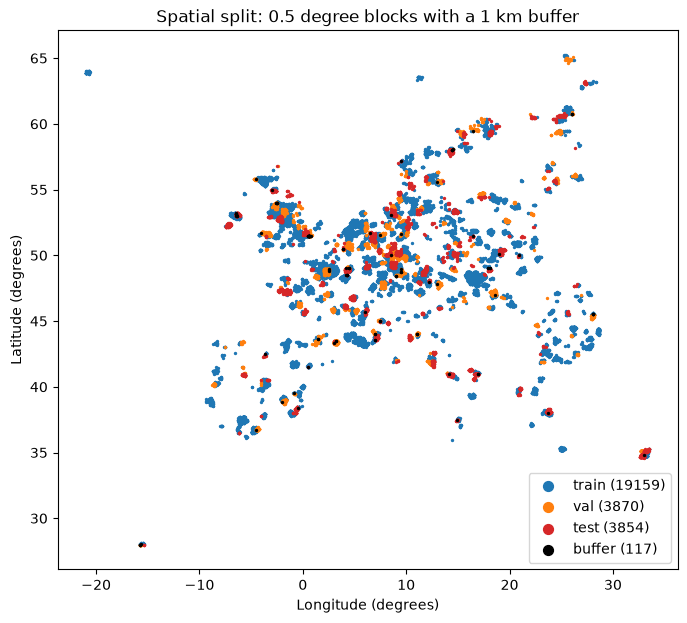

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
for split_name, colour in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:red"), ("buffer", "black")]:
    rows = split[split["split"] == split_name]
    ax.scatter(rows["lon"], rows["lat"], s=2, color=colour, label=f"{split_name} ({len(rows)})")
ax.set_title("Spatial split: 0.5 degree blocks with a 1 km buffer")
ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
ax.legend(markerscale=5)
plt.savefig(figures_dir / "spatial_split_map.png", dpi=150, bbox_inches="tight")
plt.show()

**Claim.** The final split has no training patch within 1 km of any validation or test patch, and every class has the same share in training, validation and test.

**Reasons.** Whole 0.5 degree blocks go to one split, and the buffer removes the few patches that sit next to a block edge.

**Evidence.** 19,159 training (71.0%), 3,870 validation (14.3%) and 3,854 test patches (14.3%); 117 patches (0.4%) are left out as buffer. The closest training patch to any test patch is 1.04 km away, to any validation patch 1.00 km, and the closest validation patch to any test patch is 1.09 km. The class shares in the table differ by at most 0.7 percentage points between splits (PermanentCrop: 9.2% in training, 9.9% in validation). The map shows validation and test blocks spread across the whole of Europe, not concentrated in one region.

**Warrant.** A test set that is both separated in space and balanced like the full data measures what the proposal asks: how well each model classifies parcels it has never seen. Because Pasture keeps its 7.4% share in every split, macro-F1 and per-class recall stay comparable between splits.

**Counterargument.** The split depends on how scikit-learn shuffles the groups, and a different scikit-learn version can produce a different split from the same seed. This happened during the project: re-running this notebook on another computer overwrote the split, and the models had to be retrained on the original one. Since then the split is made only once and loaded from `results/split.csv` afterwards, so it cannot change again. The versions used are printed in the first cell.

In [7]:
if not split_path.exists():
    split[["file", "class_name", "label", "lon", "lat", "block", "split"]].to_csv(split_path, index=False)
    print("Saved", len(split), "rows to results/split.csv")
else:
    print("results/split.csv already exists and is not changed")

Saved 27000 rows to results/split.csv


## 4. Normalisation from the training split only

**Clip, then scale.** Notebook 01 found rare extreme values up to about 28,000 in several bands, while 99% of the patch maxima stay far lower. A mean and standard deviation computed with those values would be pulled by a handful of pixels. So each band is first clipped to its 0.1st and 99.9th percentile, then scaled to mean 0 and standard deviation 1. Clipping at these percentiles changes only the 0.2% most extreme pixels of each band. All limits and statistics come from the training split only, so no information from validation or test data enters the preprocessing (lecture_2_introduction_to_ML.pdf, slide 24).

**The same statistics for every model, the ResNet included.** The course notebook normalises the input of a pretrained model with the ImageNet mean and standard deviation, because the input must be preprocessed the same way as during the original training (lecture_12_finetuning_live_WITH_RESULTS 1.pdf, section 1 and quick quiz question 1). We deliberately do not, for three reasons. First, ImageNet statistics describe photos with values between 0 and 1, while our bands hold raw values in the thousands: applied to them, they would not produce inputs of mean 0 and standard deviation 1, which is what that normalisation is for. Our per-band statistics do produce exactly that scale. Second, there are no ImageNet statistics for the 10 non-visible bands. Third, using one preprocessing for RGB and 13 bands keeps the comparison fair: the only difference between the two inputs is the number of bands. The course notebook itself marks a "different domain" as a case where pretrained models need care (lecture_12 live notebook, quick quiz table).

The pixel sample for the percentiles and the full pass for the mean and standard deviation read all training files twice, which takes a few minutes. Like the split, the statistics are computed only when `results/band_stats.csv` does not exist yet, and loaded otherwise, so every model uses the same values.

In [8]:
band_stats_path = results_dir / "band_stats.csv"
if band_stats_path.exists():
    band_stats = pd.read_csv(band_stats_path)
    print("Loaded the fixed statistics from results/band_stats.csv")
else:
    band_stats = compute_band_stats(train["path"], low_percentile=0.1, high_percentile=99.9,
                                    pixels_per_file=200, seed=SEED)
    band_stats.to_csv(band_stats_path, index=False)
    print("Computed and saved results/band_stats.csv")
band_stats.round(1)

,band,clip_low,clip_high,mean,std
0,B01,893.0,2626.000000,1350.0,246.0
1,B02,641.0,3542.000000,1113.8,328.6
2,B03,420.0,3644.000000,1040.3,388.8
3,B04,230.0,4019.199951,942.3,588.4
4,B05,194.0,3772.000000,1199.3,563.4
5,B06,168.0,4429.000000,2007.7,855.1
6,B07,144.0,5658.000000,2378.8,1080.2
7,B08,115.0,5581.000000,2307.7,1113.8
8,B09,53.0,2251.000000,743.3,406.0
9,B10,4.0,51.000000,12.1,4.4


**Claim.** The clip limits only touch the extreme tail of each band, far below the values of about 28,000 seen in notebook 01.

**Reasons.** The 99.9th percentile marks the value that only one pixel in a thousand exceeds, so anything above it is rare by construction.

**Evidence.** The upper limits lie between 2,251 (B09) and 6,085 (B8A) for the ground-seeing bands, and at 51 for B10, while notebook 01 found maxima of about 28,000 in several bands. The means and standard deviations are computed over all 19,159 training patches after clipping.

**Warrant.** Without clipping, a handful of pixels near 28,000 would stretch the scale of a band and squeeze the ordinary values together. With the limits, the mean and standard deviation describe the typical pixels, which the course asks us to justify ("explain your normalization choice", CNN_Class_Competition_2_Food_Classification_Explained.pdf, assignment requirements, step 5).

**Counterargument.** The clipped pixels may be real, for example bright roofs or cloud edges, and a model loses the information that they are extreme. We accept this: after clipping they still have the highest value in their band, so they remain the brightest pixels, only less far apart from the rest.

## 5. Check: normalised training patches have mean about 0 and standard deviation about 1

In [9]:
check_paths = train["path"].sample(200, random_state=SEED)
normalised = np.stack([normalise(read_bands(path), band_stats) for path in check_paths])
check = pd.DataFrame({
    "band": BAND_NAMES,
    "mean after normalising": normalised.mean(axis=(0, 2, 3)).round(2),
    "std after normalising": normalised.std(axis=(0, 2, 3)).round(2),
})
check

,band,mean after normalising,std after normalising
0,B01,-0.05,0.94
1,B02,-0.05,0.96
2,B03,-0.05,0.99
3,B04,-0.03,0.99
4,B05,-0.03,1.01
5,B06,-0.06,1.04
6,B07,-0.07,1.03
7,B08,-0.06,1.03
8,B09,-0.03,1.00
9,B10,-0.02,0.94


**Claim.** The normalisation works as intended: training patches end up with a mean close to 0 and a standard deviation close to 1 in every band.

**Evidence.** On 200 random training patches the means lie between -0.07 and -0.01 and the standard deviations between 0.94 and 1.04.

**Warrant.** Inputs on a common scale of mean 0 and standard deviation 1 are what the statistics were computed for, and they put all 13 bands on the same footing for every model.

**Counterargument.** The values are not exactly 0 and 1, because the check uses a sample of 200 patches and the clipped pixels. We accept the small differences: they are of the size expected from a sample, not a sign of an error.

## Summary

- A random split leaks: 54.6% of test patches would have a training patch within 1 km.
- Spatial split on 0.5 degree blocks with a 1 km buffer: 19,159 training, 3,870 validation and 3,854 test patches, 117 left out. No training patch lies within 1 km of a validation or test patch, and class shares are the same in every split.
- `results/split.csv` is the only source of the split. This notebook makes it only when it is missing and loads it otherwise, because another scikit-learn version could shuffle differently. The same holds for `results/band_stats.csv`.
- Each band is clipped to its 0.1st and 99.9th training percentile and scaled to mean 0 and standard deviation 1, with statistics from the training split only, saved in `results/band_stats.csv`.
- Every model, the ResNet included, uses these statistics, not the ImageNet ones.

## 6. Cache for training and the DataLoaders

**Cache for training.** Opening one GeoTIFF takes a few milliseconds, so reading 128 separate files for every batch would make training wait for the disk. `build_cache` writes all 27,000 raw patches once into `data/eurosat_cache.npy` (about 2.9 GB, ignored by Git), in the row order of `results/split.csv`. The values stay the raw whole numbers (uint16) of the GeoTIFFs, so nothing is rounded, and normalisation and haze still work on the raw values. `get_cache` builds the cache only when it is missing and otherwise just opens it, in the same way the course datasets with `download=True` only download when the data is missing (ImageClassificationML.pdf, page 2). Every training notebook starts with `get_cache`, so nobody has to run a setup step: the first notebook run on a machine builds the cache once. This section only checks that the cache is correct.

**DataLoaders.** The Dataset follows the course pattern of a class with `__len__` and `__getitem__` that returns the input tensor and the target (lecture_7_intro_to_DL-3.pdf, slide 4). Each patch is normalised with `band_stats.csv`, reduced to bands 4, 3, 2 for the RGB input, and augmented in the training split only, as the course does ("To be applied to training images only", lecture_8_DL_for_CV_1_compressed.pdf, slide 43). The augmentation is a random turn by 0, 90, 180 or 270 degrees and a random flip, instead of the 15-degree rotation of the course example: a satellite patch has no "up", so every turned or flipped version is a real-looking image, while a 15-degree turn would invent pixel values and leave empty corners on a 64 x 64 patch. Validation and test patches are not augmented, so they come out the same every time (CNN_Class_Competition_2_Food_Classification_Explained.pdf, suggested starting point). RGB and 13 bands, and the CNN and the ResNet, get exactly the same preprocessing and augmentation, so these cannot explain any difference between them. Batches hold 128 patches by default, as in the course CNN notebook (CNN_Class_Competition_2_Food_Classification_Explained.pdf, section 1).

In [10]:
from piece_of_crop import get_cache, make_loaders, read_split

cache_path = project_root / "data" / "eurosat_cache.npy"
split = read_split(results_dir / "split.csv")
cache = get_cache(split, data_dir, cache_path)
print("Cache shape:", cache.shape, cache.dtype)

Cache already exists: /Users/estellearnander/sem5/AI/piece_of_crop/data/eurosat_cache.npy
Cache shape: (27000, 13, 64, 64) uint16


In [11]:
# Check: the cache holds exactly the GeoTIFF values, at the right rows.
for row in [0, len(split) // 2, len(split) - 1]:
    path = data_dir / split.loc[row, "class_name"] / split.loc[row, "file"]
    assert np.array_equal(cache[row].astype(np.float32), read_bands(path))
print("Cache rows match the GeoTIFFs.")

for input_type in ["rgb", "13band"]:
    loaders = make_loaders(split, cache, band_stats, input_type, batch_size=128, seed=SEED)
    images, labels = next(iter(loaders["train"]))
    print(input_type, "| batch:", tuple(images.shape),
          "| batches per epoch:", {name: len(loader) for name, loader in loaders.items()})

Cache rows match the GeoTIFFs.
rgb | batch: (128, 3, 64, 64) | batches per epoch: {'train': 150, 'val': 31, 'test': 31}
13band | batch: (128, 13, 64, 64) | batches per epoch: {'train': 150, 'val': 31, 'test': 31}
